# Speech Recognition

**Seong Cho** · ACME Volume 3

**Lab objective:** simulate a Gaussian mixture model hidden Markov model (GMMHMM), then train one GMMHMM per word on MFCC features of recorded speech and use the trained models to classify spoken words.

<sub>Lab specification from the *Volume 3* lab materials of [Foundations of Applied Mathematics](https://foundations-of-applied-mathematics.github.io/) (BYU ACME), © Dr. J. Humpherys, used under [CC BY 3.0 US](http://creativecommons.org/licenses/by/3.0/us/). Problem statements are quoted from the course's lab notebook. Solutions are my own. `MFCC.py`, `gmm.py` and `gmmhmm.py` are helper modules provided with the lab.</sub>

In [1]:
import numpy as np
import MFCC
from scipy.io import wavfile
from glob import glob
import gmmhmm
import gmm
from random import shuffle
import warnings
warnings.filterwarnings("ignore")

## Problem 1: Simulating a GMMHMM

> **Problem 1.** Write a function which accepts a GMMHMM in the format above as well as an integer `n_sim`, and which simulates the GMMHMM process, generating `n_sim` different observations. Do so by implementing the following function declaration.

The format is the list `[A, weights, means, covars, pi]` described in the docstring: the transition matrix, each state's mixture weights, the means and covariances of each state's mixture components, and the initial state distribution.

In [2]:
def sample_gmmhmm(gmmhmm, n_sim):
    """
    Simulate sampling from a GMMHMM.
    
    Parameters
    ----------
    gmmhmm (list): [A, weights, means, covars, pi] for the desired GMMHMM
    n_sim (int): number of samples to return
    
    Returns
    -------
    states : ndarray of shape (n_sim,)
        The sequence of states
    obs : ndarray of shape (n_sim, K)
        The generated observations (column vectors of length K)
    """
    A, weights, means, covars, pi = gmmhmm
    N = len(pi)
    M = len(weights[0])
    K = len(means[0, 0])
    x_0 = np.random.choice(N, p=pi)
    y = np.random.choice(M, p=weights[x_0])
    z = np.random.multivariate_normal(means[x_0, y], covars[x_0, y])
    Z = [z]
    X = [x_0]  # Added: keep the states, which the docstring says to return.
    for _ in range(n_sim - 1):
        x_t = np.random.choice(N, p=A[x_0])
        y = np.random.choice(M, p=weights[x_t])
        z = np.random.multivariate_normal(means[x_t, y], covars[x_t, y])
        Z.append(z)
        X.append(x_t)  # Added.
        # Added: move to the new state. Every transition was drawn from the
        # initial state's row A[x_0], so the chain never moved past one step.
        x_0 = x_t
    # Changed: return the states as well as the observations, as documented.
    return np.array(X), np.array(Z)

The sampler draws from NumPy's global random state, seeded here so the saved output is reproducible.

In [3]:
np.random.seed(1)

In [4]:
A = np.array([[.65, .35], [.15, .85]])
pi = np.array([.8, .2])
weights = np.array([[.7, .2, .1], [.1, .5, .4]])
means1 = np.array([[0., 17., -4.], [5., -12., -8.], [-16., 22., 2.]])
means2 = np.array([[-5., 3., 23.], [-12., -2., 14.], [15., -32., 0.]])
means = np.array([means1, means2])
covars1 = np.array([5*np.eye(3), 7*np.eye(3), np.eye(3)])
covars2 = np.array([10*np.eye(3), 3*np.eye(3), 4*np.eye(3)])
covars = np.array([covars1, covars2])
_gmmhmm = [A, weights, means, covars, pi]
sample_gmmhmm(_gmmhmm, 10)

(array([0, 0, 0, 1, 1, 1, 0, 1, 0, 0]),
 array([[ 3.60258889e+00, -1.48388081e+01, -5.71034663e+00],
        [-5.14639698e+00,  1.77133931e+01, -4.55760911e+00],
        [ 3.26937274e+00,  1.23933853e+01, -4.72094679e+00],
        [ 1.42318913e+01, -2.97324611e+01, -2.19978253e+00],
        [ 1.46551436e+01, -3.37557168e+01,  8.44274934e-02],
        [-1.09905344e+01, -4.38399064e-01,  1.48703457e+01],
        [ 7.38344081e+00, -1.38089739e+01, -8.32513698e+00],
        [-1.36208002e+01, -3.19799156e+00,  1.33128027e+01],
        [-1.53656487e+00,  1.51100627e+01, -5.50095198e+00],
        [-2.83189041e-02,  2.07114305e+01, -2.34073881e+00]]))

Checks on a long simulation: the empirical transition frequencies match $A$, and each state's observations have the mean $\sum_m w_m \mu_m$ of its mixture. The initial state over many short runs matches $\pi$.

In [5]:
states, obs = sample_gmmhmm(_gmmhmm, 20000)
assert states.shape == (20000,) and obs.shape == (20000, 3)
counts = np.zeros((2, 2))
np.add.at(counts, (states[:-1], states[1:]), 1)
A_hat = counts / counts.sum(axis=1, keepdims=True)
print("empirical transition matrix:\n", A_hat.round(3))
assert np.allclose(A_hat, A, atol=0.02)
for s in range(2):
    print(f"state {s} mean: {obs[states == s].mean(axis=0).round(2)}  expected: {(weights[s] @ means[s]).round(2)}")
    assert np.allclose(obs[states == s].mean(axis=0), weights[s] @ means[s], atol=0.5)
first = np.array([sample_gmmhmm(_gmmhmm, 1)[0][0] for _ in range(4000)])
print("initial state frequencies:", np.bincount(first, minlength=2) / len(first))
assert np.allclose(np.bincount(first, minlength=2) / len(first), pi, atol=0.03)

empirical transition matrix:
 [[0.649 0.351]
 [0.15  0.85 ]]
state 0 mean: [-0.56 11.78 -4.19]  expected: [-0.6 11.7 -4.2]
state 1 mean: [ -0.47 -13.51   9.34]  expected: [ -0.5 -13.5   9.3]
initial state frequencies: [0.80575 0.19425]


## Problem 2: MFCC features

> **Problem 2.** Load the provided audio files using `scipy.io.wavfile.read`. For each of the five words/phrases (mathematics, biology, political science, psychology, statistics), use `MFCC.extract()` on each of the 30 samples, saving the resulting arrays in a list.

Besides the 30 samples, `Samples/` has one long recording (about a minute) of each word; the length check skips those. `MFCC.extract()` also draws each sample's features into the current figure, so the cell shows the MFCCs of the last sample processed.

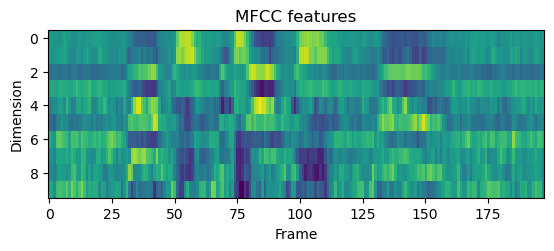

In [6]:
math = []
bio = []
poli_sci = []
psych = []
stats = []
for file in glob("Samples/*"):
    if "Mathematics" in file:
        rate, signal = wavfile.read(file)
        if len(signal) > 1e5:
            continue
        mfccs = MFCC.extract(signal)
        math.append(mfccs)
    elif "Biology" in file:
        rate, signal = wavfile.read(file)
        if len(signal) > 1e5:
            continue
        mfccs = MFCC.extract(signal)
        bio.append(mfccs)
    elif "PoliticalScience" in file:
        rate, signal = wavfile.read(file)
        if len(signal) > 1e5:
            continue
        mfccs = MFCC.extract(signal)
        poli_sci.append(mfccs)
    elif "Psychology" in file:
        rate, signal = wavfile.read(file)
        if len(signal) > 1e5:
            continue
        mfccs = MFCC.extract(signal)
        psych.append(mfccs)
    elif "Statistics" in file:
        rate, signal = wavfile.read(file)
        if len(signal) > 1e5:
            continue
        mfccs = MFCC.extract(signal)
        stats.append(mfccs)
    else:
        print(False)

In [7]:
for name, mfccs in [("math", math), ("bio", bio), ("poli_sci", poli_sci), ("psych", psych), ("stats", stats)]:
    print(f"{name:9s} {len(mfccs)} samples, frames per sample {min(len(m) for m in mfccs)} to {max(len(m) for m in mfccs)}")
    assert len(mfccs) == 30 and all(m.shape[1] == 10 for m in mfccs)

math      30 samples, frames per sample 198 to 198
bio       30 samples, frames per sample 198 to 198
poli_sci  30 samples, frames per sample 198 to 198
psych     30 samples, frames per sample 198 to 198
stats     30 samples, frames per sample 191 to 219


## Problem 3: Training a GMMHMM for each word

> **Problem 3.** Complete the function `initialize()`, which generates random starting state distributions and transition matrices. Make sure that the randomly-generated transition matrices are row-stochastic, and that the entries of `startprob` are nonnegative and sum to one.
>
> Partition each list of MFCCs into a training set of 20 samples, and a test set of the remaining 10 samples.
>
> Using the training sets, train a GMMHMM on each of the words from the previous problem with at least 10 random restarts (coming from `initialize()`, keeping the best model for each word (the one with the highest log-likelihood). This process may take several minutes.

In [8]:
def initialize(n_states):
    """
    Generates random starting state distributions and random transition matrices 
    for a Markov chain with (n_states) states.

    Parameters
    ----------
    n_states (int): number of states

    Returns
    -------
    startprob (ndarray): random array of starting probabilites
    transmat (ndarray): random row-stochastic transition matrix
    """
    pi = np.random.random(n_states)
    A = np.random.random((n_states, n_states))
    pi /= pi.sum()
    A /= A.sum(axis=1)[:,None]
    return pi, A

In [9]:
for n in [1, 5, 20]:
    startprob, transmat = initialize(n)
    assert startprob.shape == (n,) and transmat.shape == (n, n)
    assert np.all(startprob >= 0) and np.isclose(startprob.sum(), 1)
    assert np.all(transmat >= 0) and np.allclose(transmat.sum(axis=1), 1)
print(np.round(initialize(5)[1], 3))

[[0.399 0.02  0.114 0.122 0.346]
 [0.145 0.205 0.156 0.364 0.131]
 [0.081 0.23  0.542 0.113 0.035]
 [0.159 0.3   0.095 0.208 0.238]
 [0.083 0.437 0.042 0.378 0.06 ]]


The split uses Python's `random.shuffle()`, and the GMMHMM initialization uses NumPy's random state through k-means, so both are seeded here.

In [10]:
import random
random.seed(3)
np.random.seed(3)

In [11]:
shuffle(math)
shuffle(bio)
shuffle(poli_sci)
shuffle(psych)
shuffle(stats)
math_train, math_test = math[:20], math[20:]
bio_train, bio_test = bio[:20], bio[20:]
poli_sci_train, poli_sci_test = poli_sci[:20], poli_sci[20:]
psych_train, psych_test = psych[:20], psych[20:]
stats_train, stats_test = stats[:20], stats[20:]

> **Note.** Each GMMHMM fit takes several seconds here, so 10 restarts for each of the five words would take about four minutes. To keep this notebook's run time reasonable, the saved run uses 5 restarts per word; `best_model()` still defaults to the 10 the problem asks for.

In [12]:
# Changed: n_restarts parameter (default 10, as before) so this notebook can run fewer.
def best_model(samples, n_restarts=10):
    models = []
    for _ in range(n_restarts):
        startprob, transmat = initialize(5)
        model = gmmhmm.GMMHMM(n_components=5, n_mix=3, transmat=transmat, startprob=startprob, cvtype='diag')
        model.covars_prior = 0.01
        model.fit(samples, init_params='mc', var=0.1)
        models.append(model)
    return max(models, key=lambda x: x.logprob)

In [13]:
# Changed: 5 restarts per word instead of 10, to keep the run time down.
math_model = best_model(math_train, n_restarts=5)
bio_model = best_model(bio_train, n_restarts=5)
poli_sci_model = best_model(poli_sci_train, n_restarts=5)
psych_model = best_model(psych_train, n_restarts=5)
stats_model = best_model(stats_train, n_restarts=5)

In [14]:
for name, model in [("math", math_model), ("bio", bio_model), ("poli_sci", poli_sci_model),
                    ("psych", psych_model), ("stats", stats_model)]:
    print(f"{name:9s} training log-likelihood {model.logprob:.1f}")
    assert np.allclose(model.transmat.sum(axis=1), 1) and np.isclose(model.startprob.sum(), 1)

math      training log-likelihood -35927.1
bio       training log-likelihood -34144.2
poli_sci  training log-likelihood -26038.2
psych     training log-likelihood -32460.0
stats     training log-likelihood -30506.5


## Problem 4: Classifying the test samples

> **Problem 4.** Classify the 10 test samples for each word, by using the `.score()` method from each of the five optimal models, and then assigning it to the word associated with the model with the highest score. How does your system perform? Which words are the hardest to correctly classify? Make a dictionary containing the accuracy of the classification of your five testing sets. Specifically, the words/phrases will be the keys, and the values will be the percent accuracy.

In [15]:
def predict(signal):
    math_score = math_model.score(signal)
    bio_score = bio_model.score(signal)
    poli_sci_score = poli_sci_model.score(signal)
    psych_score = psych_model.score(signal)
    stats_score = stats_model.score(signal)
    scores = np.array([math_score, bio_score, poli_sci_score, psych_score, stats_score])
    best = np.argmax(scores)
    if best == 0:
        return "math"
    elif best == 1:
        return "bio"
    elif best == 2:
        return "poli_sci"
    elif best == 3:
        return "psych"
    elif best == 4:
        return "stats"

In [16]:
clf_accuracy = {"math":0, "bio":0, "poli_sci":0, "psych":0, "stats":0}
for signal in math_test:
    pred = predict(signal)
    if pred == "math":
        clf_accuracy["math"] += 1
    else:
        print("prediction: {}, actual: math".format(pred))
clf_accuracy["math"] /= 10
for signal in bio_test:
    pred = predict(signal)
    if pred == "bio":
        clf_accuracy["bio"] += 1
    else:
        print("prediction: {}, actual: bio".format(pred))
clf_accuracy["bio"] /= 10
for signal in poli_sci_test:
    pred = predict(signal)
    if pred == "poli_sci":
        clf_accuracy["poli_sci"] += 1
    else:
        print("prediction: {}, actual: poli_sci".format(pred))
clf_accuracy["poli_sci"] /= 10
for signal in psych_test:
    pred = predict(signal)
    if pred == "psych":
        clf_accuracy["psych"] += 1
    else:
        print("prediction: {}, actual: psych".format(pred))
clf_accuracy["psych"] /= 10
for signal in stats_test:
    pred = predict(signal)
    if pred == "stats":
        clf_accuracy["stats"] += 1
    else:
        print("prediction: {}, actual: stats".format(pred))
clf_accuracy["stats"] /= 10
clf_accuracy

prediction: psych, actual: bio


prediction: psych, actual: poli_sci


{'math': 1.0, 'bio': 0.9, 'poli_sci': 0.9, 'psych': 1.0, 'stats': 1.0}

The full confusion matrix of the test samples (rows are the true words, columns the predictions):

In [17]:
names = ["math", "bio", "poli_sci", "psych", "stats"]
tests = [math_test, bio_test, poli_sci_test, psych_test, stats_test]
confusion = np.array([[sum(predict(s) == pred for s in test) for pred in names] for test in tests])
print(" " * 9, " ".join(f"{n:>8s}" for n in names))
for name, row in zip(names, confusion):
    print(f"{name:9s}", " ".join(f"{c:8d}" for c in row))
assert all(len(t) == 10 for t in tests)
assert np.allclose(np.diag(confusion) / 10, [clf_accuracy[n] for n in names])

              math      bio poli_sci    psych    stats
math            10        0        0        0        0
bio              0        9        0        1        0
poli_sci         0        0        9        1        0
psych            0        0        0       10        0
stats            0        0        0        0       10
